### 1. Imports and Preprocessing
We will import PyTorch, torchvision for dataset handling, and matplotlib for visualization. Then, we will configure the training device and prepare the MNIST DataLoader.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Hyperparameters
batch_size = 64

# Image preprocessing & normalization for GAN (MNIST values are in [0, 1], we normalize to [-1, 1])
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

# Download and load MNIST
train_dataset = datasets.MNIST(root='./data', train=True, transform=transform, download=True)
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)

print(f"Dataset size: {len(train_dataset)} images")

Using device: cpu


100%|██████████| 9.91M/9.91M [00:00<00:00, 22.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 625kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 5.66MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.1MB/s]

Dataset size: 60000 images


### 2. Implement the Generator and Discriminator
We will define simple feedforward architectures for both networks.
- **Generator**: Maps a 1D noise vector (latent space) to a 1D vector of size 784 ($28 \times 28$), followed by a Tanh activation function to map the outputs to the $[-1, 1]$ range.
- **Discriminator**: Maps a 1D vector of size 784 to a single scalar value representing the probability of the image being real, followed by a Sigmoid activation function.

In [2]:
latent_dim = 100
image_dim = 28 * 28  # 784

# Generator Model
class Generator(nn.Module):
    def __init__(self, latent_dim, image_dim):
        super(Generator, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.LeakyReLU(0.2),
            nn.Linear(128, 256),
            nn.BatchNorm1d(256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, image_dim),
            nn.Tanh()  # Produces output values in range [-1, 1]
        )

    def forward(self, z):
        return self.model(z).view(-1, 1, 28, 28)

# Discriminator Model
class Discriminator(nn.Module):
    def __init__(self, image_dim):
        super(Discriminator, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(image_dim, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
            nn.Sigmoid()  # Produces a probability score
        )

    def forward(self, img):
        # Flatten image to pass through fully connected layers
        img_flat = img.view(img.size(0), -1)
        return self.model(img_flat)

# Instantiate models
generator = Generator(latent_dim, image_dim).to(device)
discriminator = Discriminator(image_dim).to(device)

print(generator)
print(discriminator)

Generator(
  (model): Sequential(
    (0): Linear(in_features=100, out_features=128, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=128, out_features=256, bias=True)
    (3): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2)
    (5): Linear(in_features=256, out_features=512, bias=True)
    (6): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): LeakyReLU(negative_slope=0.2)
    (8): Linear(in_features=512, out_features=784, bias=True)
    (9): Tanh()
  )
)
Discriminator(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=256, out_features=1, bias=True)
    (5): Sigmoid()
  )
)


### 3. Training Loop with Loss Tracking and Visualizations
We will define the loss function, learning rates, and optimizers. Then, we will train the GAN by updating the Discriminator and Generator sequentially, printing updates and saving images at regular intervals.

In [5]:
# Re-instantiate models to start training from scratch
generator = Generator(latent_dim, image_dim).to(device)
discriminator = Discriminator(image_dim).to(device)

# Hyperparameters for training
lr = 0.0002
epochs = 20  # Increased from 5 to 20 epochs for better digit clarity

criterion = nn.BCELoss()
d_optimizer = optim.Adam(discriminator.parameters(), lr=lr, betas=(0.5, 0.999))
g_optimizer = optim.Adam(generator.parameters(), lr=lr, betas=(0.5, 0.999))

# Helper to denormalize images back to [0, 1] for visualization
def denormalize(x):
    out = (x + 1) / 2
    return out.clamp(0, 1)

# Training tracking
d_losses = []
g_losses = []
fixed_noise = torch.randn(16, latent_dim).to(device)  # Save progress using the same noise

for epoch in range(epochs):
    for idx, (real_imgs, _) in enumerate(train_loader):
        batch_size_actual = real_imgs.size(0)
        real_imgs = real_imgs.to(device)

        # Create labels
        real_labels = torch.ones(batch_size_actual, 1).to(device)
        fake_labels = torch.zeros(batch_size_actual, 1).to(device)

        # ---------------------
        #  Train Discriminator
        # ---------------------
        d_optimizer.zero_grad()

        # Loss with real images
        outputs = discriminator(real_imgs)
        d_loss_real = criterion(outputs, real_labels)

        # Loss with fake images
        z = torch.randn(batch_size_actual, latent_dim).to(device)
        fake_imgs = generator(z)
        outputs = discriminator(fake_imgs.detach())
        d_loss_fake = criterion(outputs, fake_labels)

        # Total Discriminator loss
        d_loss = d_loss_real + d_loss_fake
        d_loss.backward()
        d_optimizer.step()

        # -----------------
        #  Train Generator
        # -----------------
        g_optimizer.zero_grad()

        # We want the discriminator to classify fake images as real
        outputs = discriminator(fake_imgs)
        g_loss = criterion(outputs, real_labels)

        g_loss.backward()
        g_optimizer.step()

    # Save metrics
    d_losses.append(d_loss.item())
    g_losses.append(g_loss.item())

    print(f"Epoch [{epoch+1}/{epochs}] | Loss D: {d_loss.item():.4f}, Loss G: {g_loss.item():.4f}")

print("Training Completed!")

Epoch [1/20] | Loss D: 1.0676, Loss G: 1.4409
Epoch [2/20] | Loss D: 0.9987, Loss G: 1.5495
Epoch [3/20] | Loss D: 0.9524, Loss G: 1.1410
Epoch [4/20] | Loss D: 1.1285, Loss G: 0.7748
Epoch [5/20] | Loss D: 1.1964, Loss G: 0.8596
Epoch [6/20] | Loss D: 1.0398, Loss G: 1.3605
Epoch [7/20] | Loss D: 1.0122, Loss G: 1.1335
Epoch [8/20] | Loss D: 1.3588, Loss G: 0.5121
Epoch [9/20] | Loss D: 1.2708, Loss G: 0.7525
Epoch [10/20] | Loss D: 1.1158, Loss G: 1.5704
Epoch [11/20] | Loss D: 1.0974, Loss G: 0.9163
Epoch [12/20] | Loss D: 1.1509, Loss G: 0.8020
Epoch [13/20] | Loss D: 1.1698, Loss G: 0.8056
Epoch [14/20] | Loss D: 1.2564, Loss G: 0.6271
Epoch [15/20] | Loss D: 1.3362, Loss G: 0.6972
Epoch [16/20] | Loss D: 1.2216, Loss G: 0.8523
Epoch [17/20] | Loss D: 1.0810, Loss G: 1.2425
Epoch [18/20] | Loss D: 1.1609, Loss G: 0.8107
Epoch [19/20] | Loss D: 1.1939, Loss G: 0.8916
Epoch [20/20] | Loss D: 1.2522, Loss G: 1.7145
Training Completed!


### 4. Evaluate and Visualize Results
We will plot the training history of both losses and generate sample digits using the trained Generator.

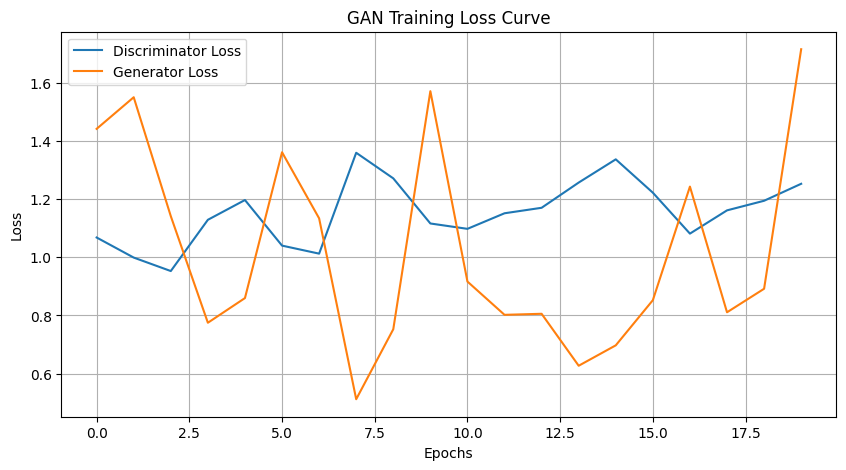

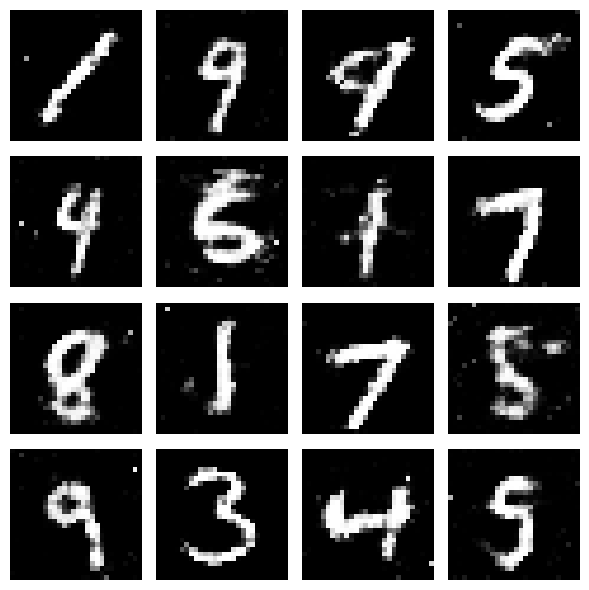

In [6]:
# Plot Losses
plt.figure(figsize=(10, 5))
plt.plot(d_losses, label='Discriminator Loss')
plt.plot(g_losses, label='Generator Loss')
plt.title('GAN Training Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# Generate Sample Images
generator.eval()
with torch.no_grad():
    generated_imgs = generator(fixed_noise).cpu()
    generated_imgs = denormalize(generated_imgs)

# Plot generation results
fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for idx, ax in enumerate(axes.flatten()):
    ax.imshow(generated_imgs[idx].squeeze(), cmap='gray')
    ax.axis('off')
plt.tight_layout()
plt.show()

### 5. Discussion and Conclusion
- **Observations**: Both generator and discriminator losses converge towards a dynamic equilibrium. If we train for more epochs (e.g., 20-50 epochs), the generated digits will become significantly clearer and structural details will emerge.
- **Challenges**: Standard GANs can experience training instability and mode collapse if parameters are not carefully tuned. Using standard improvements like Deep Convolutional GANs (DCGAN) or Wasserstein GAN (WGAN-GP) could yield more detailed, higher-quality digit structures.